Saving 생성형_AI를_더_적극적으로_이용하고_있지_않은_이유_생성형_AI의_출력_결과가_품질이_낮거나_기대에_미치지_못한다_20261029193926.csv to 생성형_AI를_더_적극적으로_이용하고_있지_않은_이유_생성형_AI의_출력_결과가_품질이_낮거나_기대에_미치지_못한다_20261029193926.csv


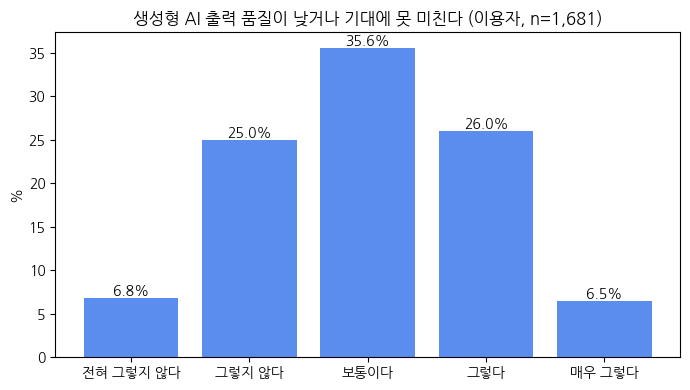

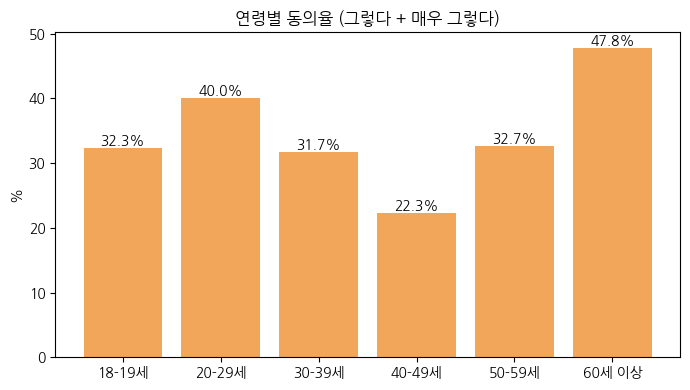

In [1]:
# 1. 한글 폰트 설치 (Colab)
!pip install -q koreanize-matplotlib

import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from google.colab import files

# 2. CSV 업로드
up = files.upload()
fname = list(up.keys())[0]

# 3. 읽기 (KOSIS CSV는 cp949, 헤더 2줄)
df = pd.read_csv(fname, encoding='cp949', header=[0, 1])
df.columns = ['구분1', '구분2', '사례수', '전혀 그렇지 않다', '그렇지 않다',
              '보통이다', '그렇다', '매우 그렇다', '평균']
df['구분1'] = df['구분1'].replace('', pd.NA).ffill()

scale = ['전혀 그렇지 않다', '그렇지 않다', '보통이다', '그렇다', '매우 그렇다']

# 4-1. 전체 응답 분포
total = df[df['구분1'] == '전체'].iloc[0]
plt.figure(figsize=(7, 4))
bars = plt.bar(scale, total[scale].astype(float), color='#5B8DEF')
plt.bar_label(bars, fmt='%.1f%%')
plt.title('생성형 AI 출력 품질이 낮거나 기대에 못 미친다 (이용자, n=1,681)')
plt.ylabel('%')
plt.tight_layout()
plt.show()

# 4-2. 연령별 동의율 (그렇다 + 매우 그렇다)
age = df[df['구분1'] == '연령별'].copy()
age['동의율'] = age['그렇다'] + age['매우 그렇다']
plt.figure(figsize=(7, 4))
bars = plt.bar(age['구분2'], age['동의율'], color='#F2A65A')
plt.bar_label(bars, fmt='%.1f%%')
plt.title('연령별 동의율 (그렇다 + 매우 그렇다)')
plt.ylabel('%')
plt.tight_layout()
plt.show()